# 08 – Extended Random Forest Forecasting

Retrain Random Forest using `data/processed/cleaned_extended_sales.csv`.

- Training period: 2013–2024
- Testing period: 2025
- Prediction level: daily demand for each store-item pair
- Original Random Forest artifacts remain unchanged.

**Data note:** The 2018–2025 portion is synthetically generated. Therefore, 2025 test metrics measure performance on the extended dataset, not independently observed real-world sales.

## 1. Import libraries

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42


## 2. Load the extended cleaned dataset

In [2]:
DATA_PATH = Path("../data/processed/cleaned_extended_sales.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}. Run notebook 05 first."
    )

df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Date range:", df["date"].min(), "to", df["date"].max())
print("\\nMissing values:\\n", df.isnull().sum())

if "data_source" in df.columns:
    print("\\nData source counts:\\n", df["data_source"].value_counts())

df.head()


Dataset shape: (2374000, 5)
Columns: ['date', 'store', 'item', 'sales', 'data_source']
Date range: 2013-01-01 00:00:00 to 2025-12-31 00:00:00
\nMissing values:\n date           0
store          0
item           0
sales          0
data_source    0
dtype: int64
\nData source counts:\n data_source
synthetic    1461000
original      913000
Name: count, dtype: int64


,date,store,item,sales,data_source
0,2013-01-01,1,1,13,original
1,2013-01-01,1,2,33,original
2,2013-01-01,1,3,15,original
3,2013-01-01,1,4,10,original
4,2013-01-01,1,5,11,original


## 3. Validate and sort the data

In [3]:
required_columns = {"date", "store", "item", "sales"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

keep_columns = ["date", "store", "item", "sales"]
df = df[keep_columns].copy()

df["date"] = pd.to_datetime(df["date"])
df["store"] = pd.to_numeric(df["store"], errors="raise").astype("int16")
df["item"] = pd.to_numeric(df["item"], errors="raise").astype("int16")
df["sales"] = pd.to_numeric(df["sales"], errors="raise")

df = df.dropna(subset=keep_columns)
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)

print("Rows:", len(df))
print("Stores:", df["store"].nunique())
print("Items:", df["item"].nunique())
print("Duplicate store-item-date rows:",
      df.duplicated(subset=["date", "store", "item"]).sum())
print("Date range:", df["date"].min(), "to", df["date"].max())


Rows: 2374000
Stores: 10
Items: 50
Duplicate store-item-date rows: 0
Date range: 2013-01-01 00:00:00 to 2025-12-31 00:00:00


## 4. Feature engineering

Create calendar and historical demand features for each store-item pair.

- `lag_1`: previous day's sales
- `lag_7`: sales seven days earlier
- `rolling_mean_7`: mean sales over the previous seven days

The rolling mean is shifted by one day to prevent target leakage.

In [4]:
df["day_of_week"] = df["date"].dt.dayofweek
df["day_of_month"] = df["date"].dt.day
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
df["is_weekend"] = (df["day_of_week"] >= 5).astype("int8")

grouped_sales = df.groupby(["store", "item"], sort=False)["sales"]

df["lag_1"] = grouped_sales.shift(1)
df["lag_7"] = grouped_sales.shift(7)

df["rolling_mean_7"] = (
    df.groupby(["store", "item"], sort=False)["sales"]
      .transform(lambda s: s.shift(1).rolling(window=7, min_periods=7).mean())
)

FEATURE_COLUMNS = [
    "store", "item", "day_of_week", "day_of_month", "month", "year",
    "is_weekend", "lag_1", "lag_7", "rolling_mean_7"
]
TARGET_COLUMN = "sales"

model_df = df.dropna(subset=FEATURE_COLUMNS + [TARGET_COLUMN]).copy()

print("Feature dataset shape:", model_df.shape)
print("Features:", FEATURE_COLUMNS)
model_df[FEATURE_COLUMNS + [TARGET_COLUMN]].head()


Feature dataset shape: (2370500, 12)
Features: ['store', 'item', 'day_of_week', 'day_of_month', 'month', 'year', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7']


,store,item,day_of_week,day_of_month,month,year,is_weekend,lag_1,lag_7,rolling_mean_7,sales
7,1,1,1,8,1,2013,0,10.000,13.000,11.857,9
8,1,1,2,9,1,2013,0,9.000,11.000,11.286,12
9,1,1,3,10,1,2013,0,12.000,14.000,11.429,9
10,1,1,4,11,1,2013,0,9.000,13.000,10.714,9
11,1,1,5,12,1,2013,1,9.000,10.000,10.143,7


## 5. Chronological train-test split

In [5]:
train_df = model_df[model_df["date"] < "2025-01-01"].copy()
test_df = model_df[
    (model_df["date"] >= "2025-01-01") &
    (model_df["date"] <= "2025-12-31")
].copy()

if train_df.empty or test_df.empty:
    raise ValueError("Training or testing data is empty. Check the date range.")

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET_COLUMN]
X_test = test_df[FEATURE_COLUMNS]
y_test = test_df[TARGET_COLUMN]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training dates:", train_df["date"].min(), "to", train_df["date"].max())
print("Testing dates:", test_df["date"].min(), "to", test_df["date"].max())


Training rows: 2188000
Testing rows: 182500
Training dates: 2013-01-08 00:00:00 to 2024-12-31 00:00:00
Testing dates: 2025-01-01 00:00:00 to 2025-12-31 00:00:00


## 6. Train the extended Random Forest model

In [6]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("Extended Random Forest training completed.")


Extended Random Forest training completed.


## 7. Generate test predictions

In [7]:
y_pred = rf_model.predict(X_test)

results = test_df[["date", "store", "item", "sales"]].copy()
results["predicted_sales"] = y_pred
results["error"] = results["sales"] - results["predicted_sales"]

results.head()


,date,store,item,sales,predicted_sales,error
4383,2025-01-01,1,1,20,20.007,-0.007
4384,2025-01-02,1,1,16,20.849,-4.849
4385,2025-01-03,1,1,22,21.804,0.196
4386,2025-01-04,1,1,21,23.272,-2.272
4387,2025-01-05,1,1,24,23.940,0.060


## 8. Evaluate model performance

In [8]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame([{
    "Model": "Extended Random Forest",
    "Training_Period": "2013-2024",
    "Testing_Period": "2025",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}])

display(metrics)
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")


,Model,Training_Period,Testing_Period,MAE,RMSE,R2
0,Extended Random Forest,2013-2024,2025,6.642,8.628,0.945


MAE: 6.6416
RMSE: 8.6276
R²: 0.9448


## 9. Visualize actual vs predicted daily sales

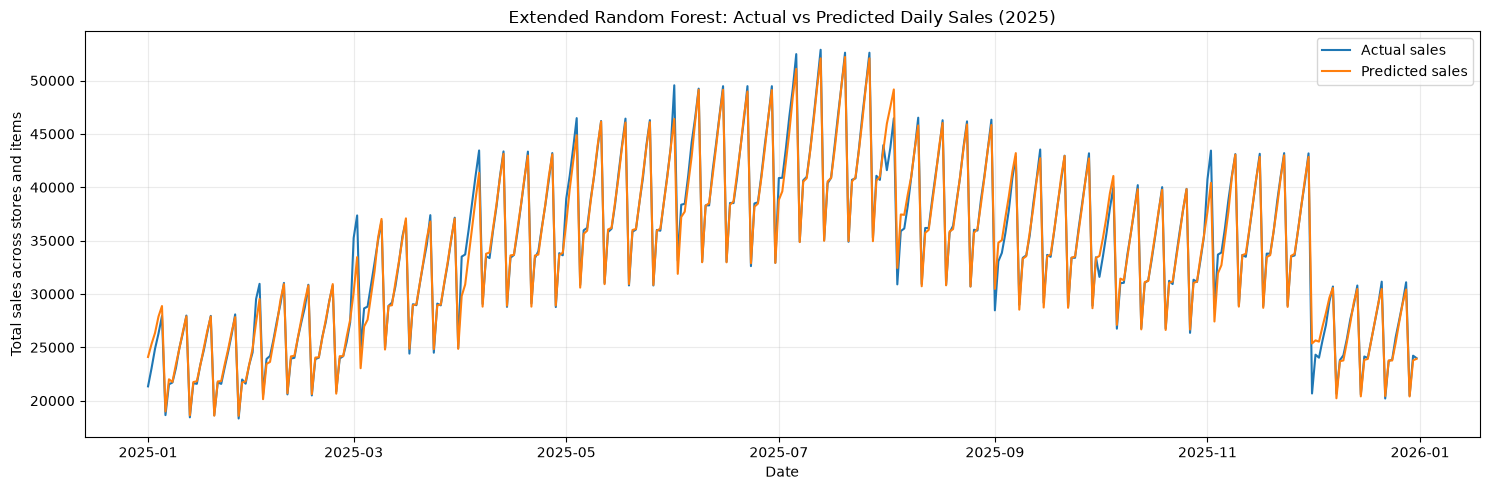

In [9]:
daily_comparison = (
    results.groupby("date")[["sales", "predicted_sales"]]
           .sum()
           .reset_index()
)

plt.figure(figsize=(15, 5))
plt.plot(daily_comparison["date"], daily_comparison["sales"], label="Actual sales")
plt.plot(daily_comparison["date"], daily_comparison["predicted_sales"],
         label="Predicted sales")
plt.title("Extended Random Forest: Actual vs Predicted Daily Sales (2025)")
plt.xlabel("Date")
plt.ylabel("Total sales across stores and items")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 10. Feature importance

,Feature,Importance
8,lag_7,0.801
9,rolling_mean_7,0.154
7,lag_1,0.022
2,day_of_week,0.019
4,month,0.002
3,day_of_month,0.001
6,is_weekend,0.001
1,item,0.000
5,year,0.000
0,store,0.000


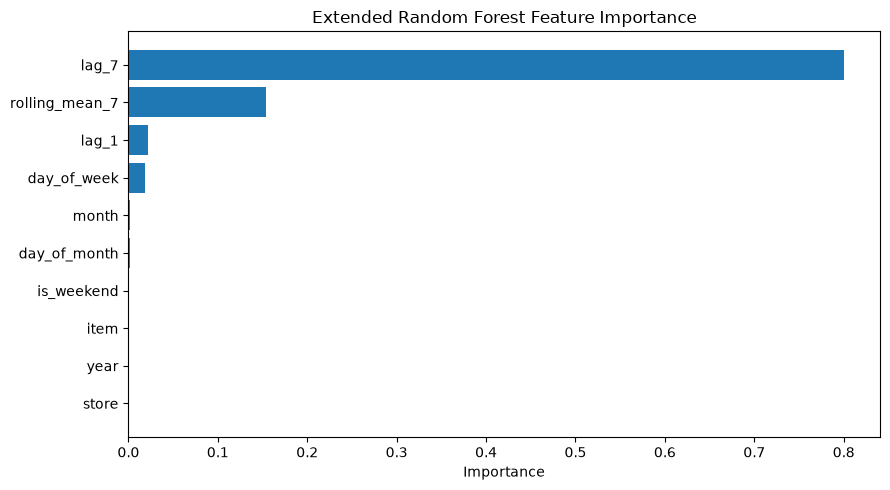

In [10]:
feature_importance = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 5))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Extended Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 11. Save the extended model and outputs

These filenames are separate from the original Random Forest artifacts. We will connect this model to FastAPI after verifying the notebook results.

In [11]:
MODEL_DIR = Path("../models")
OUTPUT_DIR = Path("../outputs")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "random_forest_extended_model.pkl"
features_path = MODEL_DIR / "random_forest_extended_features.json"

joblib.dump(rf_model, model_path)

with open(features_path, "w", encoding="utf-8") as f:
    json.dump(FEATURE_COLUMNS, f, indent=4)

metrics.to_csv(OUTPUT_DIR / "extended_random_forest_metrics.csv", index=False)
feature_importance.to_csv(
    OUTPUT_DIR / "extended_random_forest_feature_importance.csv",
    index=False
)
results.to_csv(
    OUTPUT_DIR / "extended_random_forest_2025_predictions.csv",
    index=False
)
daily_comparison.to_csv(
    OUTPUT_DIR / "extended_random_forest_daily_comparison_2025.csv",
    index=False
)

print("Saved model:", model_path.resolve())
print("Saved feature list:", features_path.resolve())
print("Saved outputs:", OUTPUT_DIR.resolve())


Saved model: C:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\models\random_forest_extended_model.pkl
Saved feature list: C:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\models\random_forest_extended_features.json
Saved outputs: C:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\outputs


## 12. Verify the saved model

In [12]:
loaded_model = joblib.load(model_path)

with open(features_path, "r", encoding="utf-8") as f:
    loaded_features = json.load(f)

sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Model reload successful:", type(loaded_model).__name__)
print("Feature order:", loaded_features)
print("Sample predictions:", np.round(sample_prediction, 2))
print("\\nExtended Random Forest experiment completed successfully.")


Model reload successful: RandomForestRegressor
Feature order: ['store', 'item', 'day_of_week', 'day_of_month', 'month', 'year', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7']
Sample predictions: [20.01 20.85 21.8  23.27 23.94]
\nExtended Random Forest experiment completed successfully.
